---
title: "Chapter 8: Loss Functions, Model Interpretation, and Multiclass Classification"
---


::: {.callout-lo}

By the end of this chapter, you will be able to:

- Compare squared, absolute, logistic, hinge, and exponential losses, and distinguish fitting loss from evaluation scores.
- Inspect linear-model coefficients and individual feature contributions with appropriate caveats.
- Explain multiclass logistic-regression predictions using class scores, softmax, and cross-entropy.
- Build and critique a complete supervised-learning workflow, and explain what its results can support.
:::


Chapter 7 introduced mean squared error for regression and log loss—also called binary cross-entropy—for binary classification. We now build on those ideas: how would a different loss change what fitting rewards? How can we inspect the predictions a fitted model makes? And how do scores, probabilities, and loss extend to classification with more than two classes?

We will first compare familiar losses with alternatives, using delivery times and binary sentiment classification. Next, sentiment and housing examples will show how coefficients and feature values combine to produce predictions. We will then extend logistic regression to three penguin species before bringing together the complete supervised-learning workflow.

Plotting code is collapsed; expand “Show plotting code” to inspect how a figure was created.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import make_column_transformer
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import accuracy_score, log_loss
from sklearn.model_selection import cross_validate, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

DATA_DIR = Path("data")


## How loss functions shape learning

### Regression: squared error versus absolute error

The prediction rule tells us how a model uses its coefficients; the loss helps determine which coefficients it learns. Starting with the squared-error loss from Chapter 7, let's see what changes when we penalize absolute errors instead.

Suppose two models predict delivery times in minutes. On four validation examples, model A's residuals are 0, 0, 0, and 8 minutes, while model B's residuals are 3, 3, 3, and 3 minutes. Model A is usually exact but makes one larger mistake. Model B is consistently a little wrong. Which would you prefer?

Before choosing a formula, decide what behaviour you want. Should one large mistake outweigh several smaller ones, or should every extra minute count equally? The answer depends partly on the consequences of an error. **Mean absolute error (MAE)** averages the magnitudes of the errors. **Mean squared error (MSE)** averages their squares. As in Chapter 7, let $r_i=y_i-\hat y_i$ denote the residual, observed minus predicted target for example $i$. With $n$ examples,

$$
\operatorname{MAE}=\frac{1}{n}\sum_{i=1}^n |r_i|,
\qquad
\operatorname{MSE}=\frac{1}{n}\sum_{i=1}^n r_i^2.
$$

The summation symbol means to add the contribution from each example. Both measures are zero for perfect predictions and increase as errors grow. Neither distinguishes an underestimate from an overestimate of the same magnitude.

In [2]:
delivery_residuals = pd.DataFrame({"Model A": [0, 0, 0, 8], "Model B": [3, 3, 3, 3]})
pd.DataFrame({
    "MAE (minutes)": delivery_residuals.abs().mean(),
    "MSE (minutes squared)": delivery_residuals.pow(2).mean(),
})


,MAE (minutes),MSE (minutes squared)
Model A,2.0,16.0
Model B,3.0,9.0


MAE favours model A: its average absolute error is 2 minutes, compared with 3 for model B. MSE favours model B: its mean squared error is 9, compared with 16 for model A. Squaring makes the single 8-minute error contribute 64 to the sum.

Doubling an error doubles its absolute loss but quadruples its squared loss. Squared error therefore gives large mistakes relatively more influence. This can be useful when large errors are especially costly, but it also makes the fitting procedure more sensitive to unusual target values. Absolute error grows more slowly; it does not make unusual observations irrelevant.

MAE is expressed in the target's units, while MSE is expressed in squared units. Do not compare their numerical values as though a smaller number across different metrics identifies the better metric. Choose a measure whose behaviour helps answer the application question. If predicting a delivery too early has a different cost from predicting it too late, neither of these symmetric losses fully captures that difference.

The delivery example shows that the choice can change which model we prefer. To understand why, compare the loss for a **single residual** $r=y-\hat y$:

$$
\ell_{\text{squared}}(r)=r^2,
\qquad
\ell_{\text{absolute}}(r)=|r|.
$$

Averaging these per-example losses gives MSE and MAE. The following curves show their different growth rates. Their numerical heights have different units; focus on how each curve changes as the residual grows.


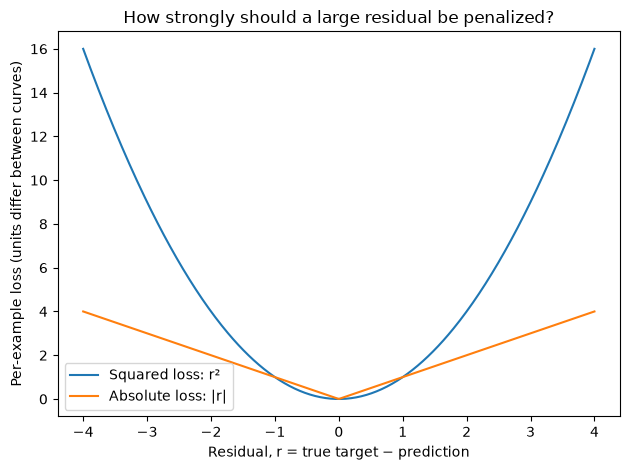

In [3]:
#| code-fold: true
#| code-summary: "Show plotting code"

residual_grid = np.linspace(-4, 4, 400)
fig, ax = plt.subplots()
ax.plot(residual_grid, residual_grid**2, label="Squared loss: r²")
ax.plot(residual_grid, np.abs(residual_grid), label="Absolute loss: |r|")
ax.set_xlabel("Residual, r = true target − prediction")
ax.set_ylabel("Per-example loss (units differ between curves)")
ax.set_title("How strongly should a large residual be penalized?")
ax.legend()
fig.tight_layout();


### Classification: log loss, hinge loss, and exponential loss

For regression, we compared penalties based on the size of a numeric error. For classification, we instead ask how strongly the model's score favours the correct class.

In Chapter 3, we used an SVM with an RBF kernel to learn nonlinear decision boundaries. An SVM can also use a **linear kernel**. For a binary classification problem with $d$ input features, this gives a linear model with $d$ weights and a bias term:

$$
z=\mathbf{w}^\mathsf{T}\mathbf{x}+b.
$$

This is the same form of score used by binary logistic regression. Both models predict one class when the score is positive and the other when it is negative, with a decision boundary at $z=0$. Logistic regression also converts the score into a probability using the sigmoid function; an SVM score is not automatically a probability.

Although their scores have the same form, the models generally learn different coefficients because they use different loss functions. Logistic regression uses log loss, while a linear SVM can use **hinge loss**. Let's compare what these losses reward. Different losses express different preferences about correct and incorrect scores.

We want the loss to decrease as a prediction moves to the correct side of the boundary, and to increase as it moves farther onto the wrong side. But should a correct prediction ever be “good enough” to incur no further penalty? And how rapidly should the penalty grow for a strongly wrong prediction?

#### Following one positive review

Consider sentiment analysis with two classes: **positive** and **negative**, which we will use again in the model-interpretation section. Positive model scores predict positive sentiment, and negative scores predict negative sentiment. Fix one review whose **true sentiment is positive**, such as “A wonderful movie.” For this review, a negative score is an incorrect prediction, while a positive score is a correct prediction. A score near zero places the review near the decision boundary.

Keeping the true sentiment fixed lets us compare the losses directly as functions of the score $z$. The formulas below apply to this positive review.

#### Logistic and hinge loss

Logistic regression assigns probability $\sigma(z)$ to positive sentiment. Since the review is truly positive, its log loss is

$$
\ell_{\text{logistic}}(z)=-\log(\sigma(z))=\log(1+e^{-z}).
$$

::: {.callout-note collapse="true" title="Why does $-\log(\sigma(z))=\log(1+e^{-z})$?"}

Recall that the sigmoid function is

$$
\sigma(z)=\frac{1}{1+e^{-z}}.
$$

Substituting this into the loss gives

$$
-\log(\sigma(z))
=-\log\left(\frac{1}{1+e^{-z}}\right)
=\log(1+e^{-z}).
$$

The last step uses $\log(1/a)=-\log(a)$: taking the log of a reciprocal changes the sign, and the minus sign outside cancels it.

:::

This is the binary log loss from Chapter 7, expressed in terms of the model's score. It decreases smoothly as the score increases, but never reaches zero for a finite score.

**Hinge loss** instead asks whether the positive review receives a sufficiently large positive score:

$$
\ell_{\text{hinge}}(z)=\max(0,1-z).
$$

It decreases linearly until $z=1$, then becomes zero. Thus a correct prediction with $0<z<1$ still incurs loss: being on the correct side alone is not enough. Scores beyond 1 incur no additional hinge loss. This is the margin idea behind SVMs. Some implementations use squared hinge loss instead.

#### A brief extension: exponential loss

Another possibility is to make the penalty grow especially quickly for strongly wrong scores:

$$
\ell_{\text{exponential}}(z)=e^{-z}.
$$

Like logistic loss, exponential loss keeps decreasing as the positive review's score grows. For very negative scores, it grows much faster than logistic or hinge loss, giving those examples considerable influence. It connects to boosting methods such as AdaBoost, which you will encounter when studying ensembles in DSCI 573; we will not develop that algorithm here.

Before looking at the plot, predict which curve will flatten to exactly zero, and which will rise fastest on the left.


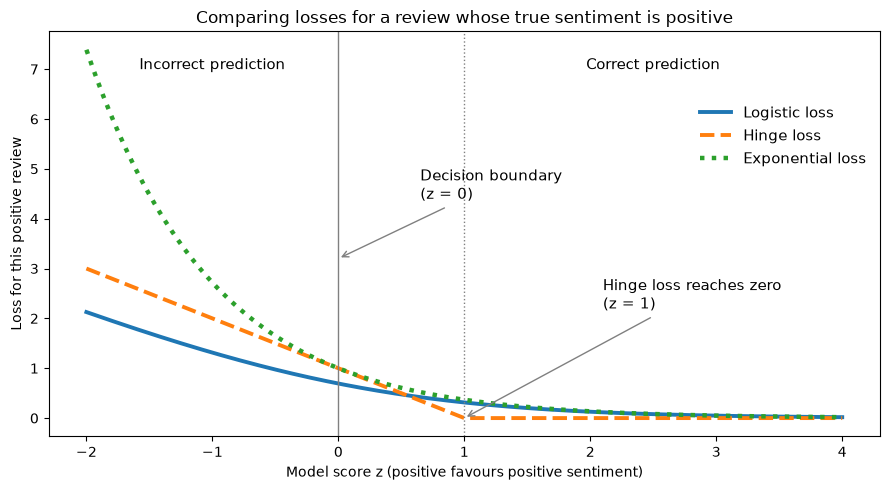

In [4]:
#| code-fold: true
#| code-summary: "Show plotting code"

review_scores = np.linspace(-2, 4, 400)
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(review_scores, np.logaddexp(0, -review_scores), label="Logistic loss", linewidth=2.8)
ax.plot(review_scores, np.maximum(0, 1 - review_scores), label="Hinge loss", linestyle="--", linewidth=2.8)
ax.plot(review_scores, np.exp(-review_scores), label="Exponential loss", linestyle=":", linewidth=3.2)
ax.axvline(0, color="gray", linewidth=1)
ax.axvline(1, color="gray", linewidth=1, linestyle=":")
ax.text(-1, 7.0, "Incorrect prediction", ha="center", fontsize=11)
ax.text(2.5, 7.0, "Correct prediction", ha="center", fontsize=11)
ax.annotate("Decision boundary\n(z = 0)", xy=(0, 3.2), xytext=(0.65, 4.4),
            ha="left", fontsize=11,
            arrowprops={"arrowstyle": "->", "color": "gray"})
ax.annotate("Hinge loss reaches zero\n(z = 1)", xy=(1, 0), xytext=(2.1, 2.2),
            ha="left", fontsize=11,
            arrowprops={"arrowstyle": "->", "color": "gray"})
ax.set_xlabel("Model score z (positive favours positive sentiment)")
ax.set_ylabel("Loss for this positive review")
ax.set_title("Comparing losses for a review whose true sentiment is positive")
ax.legend(loc="upper right", bbox_to_anchor=(1, 0.85), frameon=False, fontsize=11)
fig.tight_layout();


For this positive review, hinge loss reaches zero at a score of 1, while logistic and exponential loss continue decreasing. Exponential loss rises fastest for strongly wrong predictions. For a review whose true sentiment is **negative**, the curves are reflected horizontally: increasingly negative scores receive smaller losses. The preferred direction depends on the true class.

None of these losses is universally best: the choice changes how examples influence fitting and depends on the model family. The curves show penalties applied to model scores; an SVM score is not automatically a probability. Numerical loss values from different functions are not a shared performance scale. Use each function to understand its own penalties, then evaluate candidate models with a measure chosen for the task.


### Fitting loss versus evaluation score

A **loss** measures disagreement between a prediction and its target. During fitting, a model combines losses across the training examples to learn its parameters. Improving the loss for one review may worsen it for another, so fitting must balance their contributions. An **evaluation score** summarizes performance on the data we use to assess the fitted model. The same loss can also serve as an evaluation measure: for example, we can compute log loss on validation predictions for movie reviews.

Why fit using log loss if we care about accuracy? Accuracy stays constant as coefficients change until a predicted class changes. For a truly positive review, increasing the predicted probability of positive sentiment from 0.2 to 0.3 leaves the predicted class negative, so accuracy is unchanged. Its flat regions and jumps make accuracy difficult to optimize directly. Log loss responds to that improvement and changes smoothly with logistic regression's coefficients, giving the fitting algorithm useful guidance.

During evaluation, we choose measures that answer the practical question. Accuracy assesses whether the predicted sentiment is correct; log loss assesses the probability assigned to the true sentiment. Validation and test reviews have known sentiment labels, withheld from fitting and then used to assess predictions. We can therefore use log loss both for fitting and for evaluation on unseen examples. Some models also include a regularization penalty during fitting; you will study this in DSCI 573.

Changing the `scoring` argument of a search changes how it compares candidate models. Comparing logistic regression models using validation accuracy does not make them fit using accuracy: each still uses log loss during fitting. Switching to `scoring="neg_log_loss"` instead ranks the candidates by validation log loss. The ranking—and therefore the selected `C`—can change, even though each model's fitting loss stays the same.


### Exercise 8.1: What changed inside the search?

A logistic regression search for binary sentiment classification produces these mean validation results:

| `C` | Accuracy | Log loss |
|---:|---:|---:|
| 0.1 | 0.96 | 0.12 |
| 10 | 0.97 | 0.18 |

1. Which `C` does the search select with `scoring="accuracy"`? Which does it select with `scoring="neg_log_loss"` (smaller log loss is better)?
2. Does changing the scorer change the loss each candidate model uses to learn its coefficients?
3. If the intended use requires probability estimates, which result would you favour, and why?

::: {.callout-tip collapse="true" title="Solution"}

Accuracy selects `C=10`, while log loss selects `C=0.1`. Each candidate still uses log loss during fitting; only the search's comparison measure changes. If probability estimates are the priority, `C=0.1` has the better validation log loss despite its slightly lower accuracy. This illustrates a trade-off, rather than one model being better by every measure. Choose the comparison measure before inspecting final test results.

:::


## Model interpretation: examining coefficients

A validation score summarizes performance, but it does not explain how an individual prediction was calculated. We would like to connect the inputs, fitted parameters, and resulting prediction—and identify cases where that explanation reveals a limitation.

### Global coefficients versus individual contributions

A coefficient describes how a represented feature changes the model's score or numeric prediction, holding other represented features fixed. For regression, $w_jx_j$ contributes to the numeric prediction. For logistic regression, it contributes to the score, which is then converted into a probability. In either case, the contribution depends on both the coefficient and the example's feature value. A large coefficient contributes nothing when $x_j=0$.

We will use sentiment to reconstruct individual predictions, then housing to interpret coefficients after different kinds of preprocessing. These are explanations of fitted calculations, not evidence of causal effects.

### Sentiment-analysis demonstration

We first considered how losses treat a positive review. Now we will fit a model and inspect a mixed review, where different words push the prediction in opposite directions. Bag-of-words gives us numerical features and logistic regression gives each word a coefficient. We can inspect both the model's overall preferences and the contributions to one particular review.

The following deliberately small, authored teaching sample makes the demonstration self-contained. It is not a benchmark or evidence that the model generalizes to real reviews. The larger IMDB class demo can use the same inspection steps after a proper training-data model comparison. Here we focus on reconstructing the prediction calculation, without reporting an accuracy estimate.


In [5]:
positive_reviews = [
    "a good movie with excellent acting", "a wonderful story and a great cast",
    "an enjoyable film with a lovely ending", "brilliant acting and a compelling story",
    "a delightful movie that I enjoyed", "a great film with excellent direction",
    "wonderful performances and beautiful scenes", "an entertaining story with good acting",
]
negative_reviews = [
    "a bad movie with terrible acting", "a boring story and a poor cast",
    "an awful film with a disappointing ending", "terrible acting and a dull story",
    "a dreadful movie that I disliked", "a poor film with awful direction",
    "disappointing performances and tedious scenes", "a boring story with bad acting",
]
review_texts = positive_reviews + negative_reviews
review_labels = ["positive"] * len(positive_reviews) + ["negative"] * len(negative_reviews)
sentiment_pipeline = make_pipeline(CountVectorizer(), LogisticRegression(max_iter=1000))
sentiment_pipeline.fit(review_texts, review_labels)
vectorizer = sentiment_pipeline.named_steps["countvectorizer"]
sentiment_model = sentiment_pipeline.named_steps["logisticregression"]
print("Class order:", sentiment_model.classes_)


Class order: ['negative' 'positive']


#### Global coefficients and contributions to one review

Check the class order first. A positive coefficient pushes toward `classes_[1]`, which is positive sentiment here. A negative coefficient pushes toward negative sentiment. The coefficient describes the fitted model's association with a token, not the token's meaning in every context.


In [6]:
word_coefficients = pd.Series(
    sentiment_model.coef_[0], index=vectorizer.get_feature_names_out(),
    name="coefficient",
).sort_values()
pd.concat({
    "Most negative coefficients": word_coefficients.head(5),
    "Most positive coefficients": word_coefficients.tail(5),
})


Most negative coefficients  disappointing   -0.592167
                            terrible        -0.563280
                            awful           -0.553116
                            boring          -0.528993
                            bad             -0.522556
Most positive coefficients  delightful       0.335819
                            great            0.512306
                            good             0.514497
                            excellent        0.517288
                            wonderful        0.548021
Name: coefficient, dtype: float64

A coefficient alone is not a contribution to every prediction. A word absent from a review contributes zero. With count features, a word occurring twice contributes twice its coefficient. Let's trace the review “good good movie but terrible acting.” Before running the code, which words do you expect to push its score in each direction?


In [7]:
example_review = "good good movie but terrible acting"
review_counts = vectorizer.transform([example_review])
present = review_counts.indices
counts = review_counts.data
review_contributions = pd.DataFrame({
    "word": vectorizer.get_feature_names_out()[present],
    "count": counts,
    "coefficient": sentiment_model.coef_[0, present],
})
review_contributions["contribution"] = (
    review_contributions["count"] * review_contributions["coefficient"]
)
review_contributions.sort_values("contribution")


,word,count,coefficient,contribution
3,terrible,1,-0.563280,-0.563280
2,movie,1,-0.003208,-0.003208
0,acting,1,0.015723,0.015723
1,good,2,0.514497,1.028993


In [8]:
reconstructed_score = review_contributions["contribution"].sum() + sentiment_model.intercept_[0]
pd.Series({
    "Sum of contributions plus intercept": reconstructed_score,
    "Pipeline decision score": sentiment_pipeline.decision_function([example_review])[0],
    "P(positive)": sentiment_pipeline.predict_proba([example_review])[0, 1],
    "Predicted class": sentiment_pipeline.predict([example_review])[0],
})


Sum of contributions plus intercept    0.497419
Pipeline decision score                0.497419
P(positive)                            0.621853
Predicted class                        positive
dtype: object

#### What happens when word order or negation changes?

Now consider “good” and “not good.” We would like the model to respond to the negation, but it can only use distinctions present in its features and patterns supported by training data. What do you predict will happen in this teaching example?


In [9]:
probe_reviews = ["good", "not good", "good movie bad acting", "bad movie good acting"]
probe_results = pd.DataFrame(
    sentiment_pipeline.predict_proba(probe_reviews),
    columns=[f"P({label})" for label in sentiment_model.classes_],
    index=probe_reviews,
)
probe_results["Predicted class"] = sentiment_pipeline.predict(probe_reviews)
probe_results


,P(negative),P(positive),Predicted class
good,0.369657,0.630343,positive
not good,0.369657,0.630343,positive
good movie bad acting,0.494089,0.505911,positive
bad movie good acting,0.494089,0.505911,positive


In this sample, `not` never occurred during fitting, so the vectorizer ignores it. “Good” and “not good” therefore have identical representations. The last two reviews also have identical unigram counts despite assigning “good” and “bad” to different aspects of the movie. No classifier can recover distinctions that its input representation discarded.

Bigrams can represent a phrase such as `not good`, but adding bigrams alone would not fix this sample: the phrase must occur in the training vocabulary, and the training labels must provide useful evidence about it. Avoid removing negation words automatically when preprocessing sentiment text. Real reviews also introduce ambiguity, sarcasm, and vocabulary differences that this small example cannot assess.


### Interpreting coefficients after preprocessing

Chapter 7 used selected numerical features from King County house sales. Now suppose we also want to use ZIP code. Its numeric labels do not measure distances or an ordered quantity, so we will treat it as categorical. Our goal is to connect a mixed-feature pipeline back to feature names and coefficients.

Each row records a sale of an individual house, and `price` is its sale price in dollars. We retain the same numerical features and split as Chapter 7, then add ZIP code. This random split illustrates evaluation on similar sampled sales, rather than a claim about forecasting future market conditions. A real deployment would require checking time and repeated-property structure when choosing a split.


In [10]:
housing = pd.read_csv(DATA_DIR / "kc_house_data.csv", dtype={"zipcode": str})
numeric_features = ["sqft_living", "bedrooms", "bathrooms", "floors", "yr_built", "lat", "long"]
categorical_features = ["zipcode"]
X_housing = housing[numeric_features + categorical_features]
y_housing = housing["price"]
X_housing_train, X_housing_test, y_housing_train, y_housing_test = train_test_split(
    X_housing, y_housing, test_size=0.2, random_state=123
)
numeric_pipeline = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
categorical_pipeline = make_pipeline(
    SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore")
)
housing_preprocessor = make_column_transformer(
    (numeric_pipeline, numeric_features), (categorical_pipeline, categorical_features)
)
housing_pipeline = make_pipeline(housing_preprocessor, Ridge())


Fit a fixed `alpha=1` model on training data to inspect how it computes predictions. This demonstration focuses on interpreting coefficients after preprocessing; choosing and evaluating a final model follows the workflow you have practised in your labs. We leave the test data untouched here.

#### Recover feature names and interpret their units


In [11]:
housing_pipeline.fit(X_housing_train, y_housing_train)
housing_model = housing_pipeline.named_steps["ridge"]
housing_feature_names = housing_pipeline.named_steps["columntransformer"].get_feature_names_out()
housing_coefficients = pd.Series(
    housing_model.coef_, index=housing_feature_names, name="coefficient"
)
selected_features = [
    "pipeline-1__sqft_living", "pipeline-1__bedrooms", "pipeline-1__bathrooms",
    "pipeline-2__zipcode_98188", "pipeline-2__zipcode_98199",
]
housing_coefficients.loc[selected_features].to_frame()


,coefficient
pipeline-1__sqft_living,244805.227649
pipeline-1__bedrooms,-44013.845860
pipeline-1__bathrooms,21071.288905
pipeline-2__zipcode_98188,-176914.513645
pipeline-2__zipcode_98199,123093.668944


The transformed names link each coefficient to the feature actually received by Ridge. For standardized numerical features, a one-unit increase represents one training-set standard deviation. The living-area coefficient is about $244,805: increasing living area by one training standard deviation increases the model's predicted price by that amount, holding the other represented features fixed.

The bedroom coefficient is about −$44,014 per one-training-standard-deviation increase in bedroom count, holding living area and the other features fixed. As in Chapter 7, that is different from adding a bedroom by extending a house. It does not establish that adding a bedroom causes a house to lose value.

One-hot ZIP-code indicators remain 0 or 1, so their coefficients have a different interpretation from standardized measurements. We retained all ZIP-code categories, so there is no single omitted reference ZIP code. Switching from ZIP code 98188 to 98199 turns one indicator off and another on. The difference between their coefficients gives the change in predicted price:

$$
123{,}094-(-176{,}915)\approx\$300{,}009.
$$

This is a contrast within the fitted model, with all numerical inputs—including latitude and longitude—held fixed. Such a change may not describe a realistic pair of houses. ZIP code and coordinates contain overlapping location information, so the individual coefficients depend on how we represent location. They are not causal neighbourhood effects.

### Interpreting coefficients with care

Before explaining a coefficient, ask:

- **What feature does the model actually receive?** Check its units, preprocessing, and, for classification, which class a positive coefficient favours.
- **What is held fixed?** Overlapping features can make an isolated change unrealistic. A small coefficient does not establish that a feature is irrelevant.
- **What does this example contribute?** The contribution is $w_jx_j$, not the coefficient alone. A word absent from a review contributes zero.

Coefficients explain the fitted calculation. Whether that calculation predicts well must be assessed separately using validation data; it cannot be established from plausible-looking coefficients alone.


## Multiclass classification

### From two classes to several

So far, our classifiers have chosen between two classes. What changes when there are three or more? The ideas of scores, probabilities, and loss still apply. For multinomial logistic regression, we extend the binary approach by calculating one score per class and converting those scores into probabilities.

Suppose we have measurements of a penguin and want to predict its species: **Adelie, Chinstrap, or Gentoo**. We will use the [Palmer Penguins dataset](https://allisonhorst.github.io/palmerpenguins/), which contains measurements of 344 penguins, as our running example. A local copy of the project's CC0 data is included with the book.

![The three penguin species: Chinstrap (left), Gentoo (centre), and Adelie (right). Artwork by @allison_horst, from the Palmer Penguins project.](img/palmer-penguin-species.png){width=85% fig-alt="Illustrations of Chinstrap, Gentoo, and Adelie penguins, shown side by side."}

Our inputs are four numerical measurements: bill length, bill depth, and flipper length in millimetres, and body mass in grams. The target is species. Here are ten observations from the dataset, with their original row indices so that we can refer back to individual penguins:



In [12]:
penguins = pd.read_csv(DATA_DIR / "penguins.csv")
penguin_features = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
# Four Adelie, three Chinstrap, and three Gentoo observations.
penguin_preview_indices = [0, 1, 2, 4, 276, 277, 278, 152, 153, 154]
penguins.loc[penguin_preview_indices, penguin_features + ["species"]]

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,species
0,39.1,18.7,181.0,3750.0,Adelie
1,39.5,17.4,186.0,3800.0,Adelie
2,40.3,18.0,195.0,3250.0,Adelie
4,36.7,19.3,193.0,3450.0,Adelie
276,46.5,17.9,192.0,3500.0,Chinstrap
277,50.0,19.5,196.0,3900.0,Chinstrap
278,51.3,19.2,193.0,3650.0,Chinstrap
152,46.1,13.2,211.0,4500.0,Gentoo
153,50.0,16.3,230.0,5700.0,Gentoo
154,48.7,14.1,210.0,4450.0,Gentoo


In Chapter 7, one probability and its complement described two countries. With three species, knowing the probability of Adelie does not tell us how to divide the remaining probability between the other two classes.

This is **multiclass classification**: each example has exactly one target class among several possibilities. In **multilabel classification**, an example can have several labels at once, for instance, a photograph tagged both “penguin” and “snow”. We focus on multiclass classification here. Numeric class labels are identifiers, not quantities with an order or distance.

### From class scores to probabilities

We want one probability for each class. The probabilities should be nonnegative, sum to 1, and assign more probability to classes with larger scores. Applying a separate sigmoid to each score would not generally make the results sum to 1.

**Multinomial logistic regression** starts with a linear score for each class:

$$
z_k=\mathbf{w}_k^\mathsf{T}\mathbf{x}+b_k.
$$

Here $k$ identifies a class. Each class has its own coefficients and intercept, so the same penguin can receive different scores for different species. Here $\mathbf{x}$ contains its four measurements after preprocessing.

Consider penguin 0, whose true species is Adelie. Suppose the model assigns scores of 2 for Adelie, 1 for Chinstrap, and 0 for Gentoo. These scores are illustrative; we will fit a model later using the training portion of the dataset.

We convert the scores into probabilities with **softmax**. First exponentiate each score to obtain a positive number; then divide by the sum of those numbers:

| Species | Raw score | Exponentiated score | Probability |
|---|---:|---:|---:|
| Adelie | 2 | $e^2\approx7.389$ | $7.389/11.107\approx0.665$ |
| Chinstrap | 1 | $e^1\approx2.718$ | $2.718/11.107\approx0.245$ |
| Gentoo | 0 | $e^0=1$ | $1/11.107\approx0.090$ |

In general, with $K$ classes,

$$
p_k=\frac{e^{z_k}}{\sum_{j=1}^K e^{z_j}}.
$$

The denominator is shared by all classes, so their probabilities sum to 1. Increasing one score while holding the others fixed raises its probability and lowers the others. Softmax makes the classes compete within one probability distribution. It defines the model's probability calculation; it does not guarantee reliable estimates on new data.

Let's reproduce the calculation with NumPy. Before exponentiating, we subtract the largest score from every score. This leaves the softmax probabilities unchanged because it multiplies every numerator and the denominator by the same factor. It also avoids exponentiating large positive scores:


In [13]:
scores = np.array([2.0, 1.0, 0.0])
classes = ["Adelie", "Chinstrap", "Gentoo"]
weights = np.exp(scores - scores.max())
probabilities = weights / weights.sum()
pd.Series(probabilities, index=classes)

Adelie       0.665241
Chinstrap    0.244728
Gentoo       0.090031
dtype: float64

In practice, `scipy.special.softmax` performs these steps for us using a numerically stable implementation. Applying it to the same scores gives the same probabilities, in the same class order:


In [14]:
from scipy.special import softmax

pd.Series(softmax(scores), index=classes)

Adelie       0.665241
Chinstrap    0.244728
Gentoo       0.090031
dtype: float64

### Cross-entropy: extending binary classification

The predicted class has the largest probability: Adelie for penguin 0, matching its target class in our dataset. No class needs to exceed 0.5. Probabilities of 0.40, 0.35, and 0.25 also select Adelie. They express a different degree of preference, even though the predicted class is unchanged.

The principle behind log loss is unchanged: take the negative log of the probability assigned to the true class. We still want low loss when the model assigns high probability to the true class, and a large penalty when it confidently favours a wrong class.

Consider penguin 276 in our preview table. Its true species is Chinstrap. Suppose the model assigns probabilities of 0.1, 0.8, and 0.1 to Adelie, Chinstrap, and Gentoo, respectively. Its loss is simply

$$
L=-\log(0.8)\approx0.223.
$$

To write this calculation for any of the three species, represent the target using one indicator per class and list the probabilities in the same order:

$$
\mathbf{y}=\begin{bmatrix}0\\1\\0\end{bmatrix},
\qquad
\hat{\mathbf{p}}=\begin{bmatrix}0.1\\0.8\\0.1\end{bmatrix}.
$$

This is a **one-hot target**: only the true class has indicator 1. Multiplying each log probability by its indicator selects the true-class term, giving the same loss:

$$
L=-[0\log(0.1)+1\log(0.8)+0\log(0.1)]
=-\log(0.8)\approx0.223.
$$

For $K$ classes, let $\hat p_k$ be the model's predicted probability of class $k$, and $y_k$ be its target indicator. **Multiclass cross-entropy**, also called multiclass log loss, is

$$
L=-\sum_{k=1}^{K}y_k\log(\hat p_k)
=-\log(\hat p_{\text{true class}}).
$$

Only one term contributes, so this is the same true-class loss used in Chapter 7. Giving the true class probability 0.05 instead of 0.8 would increase the loss to about 2.996.

::: {.callout-note collapse="true" title="Notation and implementation"}

To recover **binary cross-entropy**, let $y$ be the indicator for class 1 and $\hat p$ its predicted probability. The other class then has indicator $1-y$ and probability $1-\hat p$:

$$
L=-[y\log(\hat p)+(1-y)\log(1-\hat p)].
$$

The binary formula is therefore the two-class case of the general formula. These are different ways to express the same principle, not unrelated losses.

For several examples, use $y_{ik}$ and $\hat p_{ik}$ to identify both example $i$ and class $k$. The mean cross-entropy is $-\frac{1}{n}\sum_{i=1}^{n}\sum_{k=1}^{K}y_{ik}\log(\hat p_{ik})$.

One-hot target notation is distinct from one-hot encoding input features. Scikit-learn accepts ordinary class labels for `LogisticRegression`; you do not need to construct these target vectors. The numerical class labels identify categories, not an order or distance between species.
:::

### Exercise 8.2: Is a log loss of 1.10 good?

A model achieves a mean validation log loss of 1.10 on a three-species penguin classification problem, using natural logarithms.

1. What loss would a baseline receive if it assigned probability $1/3$ to every class for every example?
2. Does the model's result provide convincing evidence of useful predictions?
3. If some classes are much more common than others, what additional baseline would you compare against?

::: {.callout-tip collapse="true" title="Solution"}

The uniform-probability baseline always assigns the true class probability $1/3$, so its loss on every example, and therefore its mean loss, is

$$
-\log(1/3)=\log(3)\approx1.099.
$$

The model's loss of 1.10 is slightly worse than the uniform baseline's 1.099. It provides no evidence of improvement over that baseline on these validation examples, although such a small difference could reflect variation in the validation sample. A loss needs a reference point, not just a judgment that its numerical value looks small.

If classes are imbalanced, also compare with a baseline that predicts the **training-set class proportions**, evaluated on the same validation data. That baseline can improve on uniform probabilities without using any features.

Assigning uniform probabilities is different from randomly guessing a single class. Log loss evaluates a probability distribution over all classes, not just a chosen class label.

:::


### Fitting a species classifier

We now fit a model to predict species from the same four measurements. Island and sex are available but omitted so that we can focus on multiclass predictions. The housing example showed how to include categorical features when needed. Our goal here is to trace predictions, so we use a fixed pipeline and training-data cross-validation rather than repeat a full search.

Some measurements are missing, and body mass has a different numerical scale from the lengths. We therefore impute missing measurements with training medians and standardize the features before fitting logistic regression. We reserve test data first and keep both transformations inside the pipeline so that each cross-validation fold learns its medians and scaling statistics from its training portion only.

The `lbfgs` solver supports multinomial logistic regression for this target. Compare against a baseline that returns the training class proportions. We report both accuracy and log loss: one describes class decisions, the other evaluates probabilities.


In [15]:
X_penguins = penguins[penguin_features]
y_penguins = penguins["species"]
X_penguins_train, X_penguins_test, y_penguins_train, y_penguins_test = train_test_split(
    X_penguins, y_penguins, test_size=0.25, random_state=571, stratify=y_penguins
)
penguin_pipeline = make_pipeline(
    SimpleImputer(strategy="median"), StandardScaler(),
    LogisticRegression(solver="lbfgs", max_iter=1000),
)
penguin_results = []
for name, model in {
    "Class-proportion baseline": DummyClassifier(strategy="prior"),
    "Logistic regression": penguin_pipeline,
}.items():
    scores = cross_validate(
        model, X_penguins_train, y_penguins_train, cv=5,
        scoring={"accuracy": "accuracy", "log_loss": "neg_log_loss"},
    )
    penguin_results.append({
        "Model": name,
        "Mean CV accuracy": scores["test_accuracy"].mean(),
        # Reverse the negative-loss scorer so smaller reported losses are better.
        "Mean CV log loss": -scores["test_log_loss"].mean(),
    })
pd.DataFrame(penguin_results).set_index("Model")

,Mean CV accuracy,Mean CV log loss
Model,,
Class-proportion baseline,0.441855,1.049318
Logistic regression,0.976697,0.068490


Logistic regression improves on the class-proportion baseline by both measures: mean cross-validation accuracy rises from about 0.442 to 0.977, while mean log loss falls from about 1.049 to 0.068. The measurements improve both class prediction accuracy and the log loss of the assigned probabilities.

Now fit the fixed pipeline on the training data and return to five penguins from our opening table, including penguins 0 and 276 from the hand calculations. All five belong to the training split. Their probabilities below come from the fitted model, rather than the illustrative scores used earlier. These training predictions let us trace the calculation; cross-validation provides the performance estimate. The test set remains untouched.


In [16]:
penguin_pipeline.fit(X_penguins_train, y_penguins_train)
penguin_examples = X_penguins_train.loc[[0, 2, 276, 277, 152]]
penguin_predictions = pd.DataFrame(
    penguin_pipeline.predict_proba(penguin_examples),
    columns=penguin_pipeline.classes_, index=penguin_examples.index,
)
penguin_predictions["Predicted class"] = penguin_pipeline.predict(penguin_examples)
penguin_predictions["True class"] = y_penguins_train.loc[penguin_examples.index]
penguin_predictions

,Adelie,Chinstrap,Gentoo,Predicted class,True class
0,0.989180,0.010441,0.000379,Adelie,Adelie
2,0.906160,0.089200,0.004640,Adelie,Adelie
276,0.066324,0.924243,0.009433,Chinstrap,Chinstrap
277,0.015806,0.981185,0.003009,Chinstrap,Chinstrap
152,0.000706,0.003323,0.995971,Gentoo,Gentoo


Each probability column follows the order in `classes_`; the largest identifies the predicted species. Adding classes does not remove the model's linear restriction: the pairwise decision boundaries remain linear in the represented features.


### Class predictions versus probability predictions

The distinction between accuracy and log loss also carries over from binary classification. Accuracy uses only the predicted species; log loss uses the probability assigned to the true species. Let's apply both ideas to the actual probabilities we just obtained for five penguins from the fitted model. Before running the next cell, compare the probability assigned to each penguin's true species. Which penguin will have the largest loss? Would accuracy distinguish two correct predictions with different true-species probabilities?

We extend the prediction table with an indicator of correctness and the loss for each penguin.


In [17]:
penguin_losses = penguin_predictions.copy()
# Look up the probability in each penguin's true-species column.
penguin_losses["P(true species)"] = [
    penguin_predictions.loc[index, species]
    for index, species in penguin_predictions["True class"].items()
]
penguin_losses["Correct"] = (
    penguin_losses["Predicted class"] == penguin_losses["True class"]
)
penguin_losses["Log loss"] = -np.log(penguin_losses["P(true species)"])
penguin_losses.sort_values("Log loss", ascending=False)

,Adelie,Chinstrap,Gentoo,Predicted class,True class,P(true species),Correct,Log loss
2,0.906160,0.089200,0.004640,Adelie,Adelie,0.906160,True,0.098540
276,0.066324,0.924243,0.009433,Chinstrap,Chinstrap,0.924243,True,0.078780
277,0.015806,0.981185,0.003009,Chinstrap,Chinstrap,0.981185,True,0.018994
0,0.989180,0.010441,0.000379,Adelie,Adelie,0.989180,True,0.010879
152,0.000706,0.003323,0.995971,Gentoo,Gentoo,0.995971,True,0.004037


The table is sorted from largest to smallest loss. All five predictions are correct, but their losses differ: penguin 2 receives a true-species probability of about 0.906 and a loss of 0.099, while penguin 152 receives probability 0.996 and a loss of 0.004. Compare the correctness column with the probability assigned to the true species: accuracy counts each correct prediction equally, while log loss distinguishes how much probability the model assigned to the observed outcome. Even two correct predictions can have different losses.

Making probabilities more extreme does not always help. Making a wrong prediction more confident increases log loss when it reduces the probability assigned to the true species. Log loss follows the same principle for two classes or several: assigning more probability to the true class reduces the loss.


### Exercise 8.3: Same class prediction, different evidence

Two models assign probabilities to Adelie, Chinstrap, and Gentoo. Model A returns (0.40, 0.35, 0.25), while model B returns (0.90, 0.05, 0.05).

What does each model predict? Which receives lower log loss if the true class is Adelie? What if it is Chinstrap? Explain why accuracy alone cannot distinguish these models on this penguin.

::: {.callout-tip collapse="true" title="Solution"}
Both predict Adelie. If Adelie is observed, model B has lower loss because it assigned 0.90 to that class rather than 0.40. If Chinstrap is observed, model A has lower loss because it assigned 0.35 rather than 0.05. Accuracy counts both as correct in the first case and both as incorrect in the second; it ignores their probabilities.
:::

## Putting the complete workflow together

### Our supervised-learning workflow so far

You have been practising this workflow in your labs. Each week, we have added tools and decisions: first a prediction task and baseline, then data splitting and cross-validation, preprocessing pipelines, comparisons between model families, and systematic hyperparameter search. These are parts of one analysis, rather than separate recipes.

Our workflow so far is:

1. **Define the task and available features.** Identify what one example represents, what you want to predict, and which inputs will be available when a prediction is needed.
2. **Reserve test data.** Choose a split appropriate for the intended prediction setting and protect the test set during development.
3. **Explore training data.** Check distributions, missingness, unusual values, and possible leakage.
4. **Build preprocessing pipelines.** Use suitable transformations for each feature type and keep learned preprocessing inside cross-validation.
5. **Establish a baseline and compare plausible models.** Compare their validation results using consistent splits and a clearly identified score.
6. **Tune promising approaches.** Use grid or randomized search within a sensible computation budget, then select a workflow using training-data validation results.
7. **Interpret the fitted model and inspect its mistakes.** Examine what the model learned and where its predictions are unreliable.
8. **Evaluate on the test set.** Assess the selected workflow after development choices are settled.
9. **Communicate findings and limitations.** Explain performance relative to a baseline and what the evidence can and cannot support.

### Using interpretation during model development

Interpretation is a step in the **analysis workflow**, rather than a transformer added to a scikit-learn `Pipeline`. The sentiment example let us reconstruct a prediction and identify distinctions the representation discarded. The housing example showed why preprocessing and overlapping features matter when explaining coefficients.

If inspection suggests changes to the representation or model, return to training-data development and comparison. Keep the test set for final assessment. Report the task, baseline, evaluation procedure, and limitations alongside the results. If final test results disappoint, report them rather than repeatedly tuning against the same test set.


### Exercise 8.4: Review a proposed workflow

Apply the workflow to a new setting: a team wants to route support requests to three departments. It includes a field recording which department eventually resolved each request, builds a text vocabulary using all requests, and then creates a train/test split. It tries many values of `C`, keeps the one with the best test accuracy, and reports that accuracy as evidence that its probability predictions are reliable.

Identify the problems and propose a corrected workflow using tools from this book. Explain which choices must be settled before final test evaluation.

::: {.callout-tip collapse="true" title="Solution"}
The resolving department is not available when a new request arrives and would reveal information about the outcome. Remove it and check the availability of the remaining inputs. Reserve the test set before learning a vocabulary; place `CountVectorizer` and the model in a pipeline so that each cross-validation fold learns its vocabulary only from that fold's training portion. Use training-data cross-validation to choose `C`, and compare against a baseline. Decide whether the intended use requires hard routing decisions, probability estimates, or both, and choose evaluation measures accordingly. Accuracy alone does not assess the assigned probabilities. Evaluate the selected workflow once on the test set and explain the limits of that evidence.
:::


## What you can do now and what comes next

You began this course with data tables and prediction tasks. You can now define a supervised-learning problem, represent numerical, categorical, and text features, establish baselines, compare model families, and tune a complete pipeline. You can separate development from final evaluation and inspect what a fitted model has learned.

The curriculum map places this foundation in the wider MDS machine-learning sequence:

![MDS machine-learning curriculum map showing how supervised-learning fundamentals connect to model selection, neural networks, unsupervised learning, and advanced machine learning.](img/MDS-ML-map.png){fig-alt="DSCI 571 supplies supervised-learning fundamentals. DSCI 573 develops evaluation, feature and model selection, regularization, and interpretation; DSCI 572 develops optimization and neural networks. DSCI 563 covers unsupervised learning and DSCI 575 extends representations and neural networks into advanced machine learning. Arrows show conceptual connections, not formal prerequisites." width="100%"}

DSCI 573 deepens evaluation, selection, regularization, and interpretation. DSCI 572 builds on weighted sums and loss functions to develop optimization and neural networks. DSCI 563 explores structure in unlabelled data, while DSCI 575 extends representations and neural networks into advanced applications. The map's arrows show conceptual connections rather than formal prerequisites.

Some questions now deserve a closer look:

| Question remaining | Connection to DSCI 573 |
|---|---|
| Is accuracy sufficient when different mistakes have different consequences? | Evaluation metrics |
| Can combining models improve predictions? | Ensembles |
| How should we control flexibility beyond this introduction? | Regularization |
| How can we explain predictions from more complex models? | Model transparency and SHAP |
| How could we represent the available information more usefully? | Feature engineering |
| Which features should we retain? | Feature selection |

Feature engineering develops useful representations of the available information; feature selection decides which inputs to retain. Like preprocessing and hyperparameter selection, these choices belong inside model development and validation. The next courses will extend the workflow you already know.


## Summary

- Squared and absolute losses place different relative weight on large prediction errors. Hinge loss becomes zero beyond a margin, while logistic and exponential losses continue decreasing for increasingly correct scores.
- Fitting uses a loss to learn parameters; evaluation measures assess the resulting predictions. Changing a search's scorer changes how candidates are compared, not each estimator's fitting loss.
- Interpreting a linear prediction requires both coefficients and feature values. Preprocessing, class order, and overlapping information matter; coefficients describe the fitted calculation rather than causal effects.
- Multiclass logistic regression computes one score per class and uses softmax to obtain probabilities that sum to 1. The largest probability determines the prediction, even when it is below 0.5.
- Cross-entropy evaluates the probability assigned to the true class. Accuracy uses only the chosen class, so correct predictions can have different log losses.
